# Machine Learning Capstone Project (23CSE301) — Review 1
## Track 1: Full Regression Track — Seoul Bike Sharing Demand Prediction

### 1. Project Overview
- **Course**: 23CSE301 Machine Learning
- **Academic Year**: 2026–27
- **Submission Scope**: Review 1 (Full Regression Track)
- **Dataset**: Seoul Bike Sharing Dataset (`Data/regression/SeoulBikeData.csv`)
- **Target Variable**: `Rented Bike Count` (continuous hourly bike rental demand)
- **Primary Tooling**: Python 3, scikit-learn, Pandas, NumPy, Matplotlib, Seaborn

This notebook implements an end-to-end Machine Learning pipeline for hourly bike rental demand forecasting. The workflow adheres strictly to academic standards and the course rubric:
1. Systematic dataset audit and exploratory data analysis covering **every single predictor feature**.
2. Rigorous data cleaning, outlier investigation, and quantile-stratified train/test splitting.
3. Domain-justified feature engineering (temporal and cyclical encoding) with strict leakage prevention.
4. Comprehensive implementation and benchmarking of all **ten required regression algorithms** on a single held-out test split.
5. Hyperparameter tuning on selected models (Random Forest and SVR) with transparent baseline-vs-tuned comparison.
6. 5-fold cross-validation on the top two models to verify generalization stability.
7. Diagnostic visualizations (Predicted vs. Actual, Residual distribution, and Tree feature importances).

### 2. Problem Definition
Public bike-sharing programs enhance urban mobility, reduce automotive traffic congestion, and lower carbon emissions. However, maintaining operational efficiency requires matching bicycle availability with fluctuating spatial and temporal demand. Severe bike shortages at docking stations frustrate commuters, while oversupply causes station congestion and unnecessary logistics costs for rebalancing.

**Analytical Objective**:
Formulate a supervised regression task to predict the continuous hourly quantity of rented bicycles ($y = \text{Rented Bike Count}$) as a function of environmental weather conditions (temperature, humidity, solar radiation, precipitation, visibility, wind speed) and temporal calendar indicators (hour, season, day of week, rush hour, holidays, functioning status).

**Mathematical Formulation**:
Given feature vector $\mathbf{x}_i \in \mathbb{R}^d$, learn a predictive function $f: \mathbb{R}^d \to \mathbb{R}$ such that the expected generalization loss (measured via $R^2$, RMSE, and MAE) on unseen test observations is minimized:
$$\min_f \frac{1}{N} \sum_{i=1}^N \mathcal{L}(y_i, f(\mathbf{x}_i))$$

### 3. Environment Setup & Dataset Loading
We import required numerical, visualization, and machine learning libraries. A global random seed `RANDOM_STATE = 42` is established to ensure total reproducibility across all stochastic splits and algorithms.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
palette = sns.color_palette('tab10')

# Global seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment initialized successfully. Python version:", sys.version.split()[0])

Environment initialized successfully. Python version: 3.13.6


We locate and load `SeoulBikeData.csv`. Because the original dataset file contains degree symbols (`°C`) in the column headers (`Temperature(°C)` and `Dew point temperature(°C)`), it requires `latin1` (or `cp1252`) encoding for clean parsing. Column names are standardized to snake_case format for clarity and coding ergonomics.

In [2]:
# Load dataset with verified encoding
csv_path = os.path.join('..', 'data', 'Regression', 'SeoulBikeData.csv')
if not os.path.exists(csv_path):
    # Fallback to local execution directory if running from repo root
    csv_path = os.path.join('data', 'Regression', 'SeoulBikeData.csv')

df_raw = pd.read_csv(csv_path, encoding='latin1')

# Explicitly map column names to clean, readable identifiers
column_mapping = {
    'Date': 'Date',
    'Rented Bike Count': 'Rented_Bike_Count',
    'Hour': 'Hour',
    'Temperature(ºC)': 'Temperature_C',
    'Temperature(°C)': 'Temperature_C',
    'Humidity(%)': 'Humidity_pct',
    'Wind speed (m/s)': 'Wind_Speed_m_s',
    'Visibility (10m)': 'Visibility_10m',
    'Dew point temperature(ºC)': 'Dew_Point_Temp_C',
    'Dew point temperature(°C)': 'Dew_Point_Temp_C',
    'Solar Radiation (MJ/m2)': 'Solar_Radiation_MJ_m2',
    'Rainfall(mm)': 'Rainfall_mm',
    'Snowfall (cm)': 'Snowfall_cm',
    'Seasons': 'Seasons',
    'Holiday': 'Holiday',
    'Functioning Day': 'Functioning_Day'
}

# Apply mapped names
df = df_raw.rename(columns=lambda c: column_mapping.get(c, c.strip().replace(' ', '_')))
# Double check any remaining unmapped temperature variations
for c in df.columns:
    if 'Temperature' in c and 'Dew' not in c:
        df.rename(columns={c: 'Temperature_C'}, inplace=True)
    elif 'Dew' in c:
        df.rename(columns={c: 'Dew_Point_Temp_C'}, inplace=True)

print(f"Dataset successfully loaded: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head(5)

Dataset successfully loaded: 8,760 rows and 14 columns.


,Date,Rented_Bike_Count,Hour,Temperature_C,Humidity_pct,Wind_Speed_m_s,Visibility_10m,Dew_Point_Temp_C,Solar_Radiation_MJ_m2,Rainfall_mm,Snowfall_cm,Seasons,Holiday,Functioning_Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### 4. Dataset Audit
A thorough dataset audit establishes baseline data integrity by examining dimensions, column data types, missing value counts, duplicate rows, and statistical summaries.

In [3]:
# Compile dataset metadata audit table
audit_dict = {
    'Column Name': df.columns,
    'Data Type': [df[col].dtype for col in df.columns],
    'Non-Null Count': [df[col].notnull().sum() for col in df.columns],
    'Null Count': [df[col].isnull().sum() for col in df.columns],
    'Null Percentage (%)': [(df[col].isnull().sum() / len(df)) * 100 for col in df.columns],
    'Unique Values': [df[col].nunique() for col in df.columns],
    'Sample Value': [df[col].iloc[0] for col in df.columns]
}
audit_df = pd.DataFrame(audit_dict)
print(f"Total duplicate rows detected: {df.duplicated().sum()}")
display(audit_df)

Total duplicate rows detected: 0


,Column Name,Data Type,Non-Null Count,Null Count,Null Percentage (%),Unique Values,Sample Value
0,Date,object,8760,0,0.0,365,01/12/2017
1,Rented_Bike_Count,int64,8760,0,0.0,2166,254
2,Hour,int64,8760,0,0.0,24,0
3,Temperature_C,float64,8760,0,0.0,546,-5.2
4,Humidity_pct,int64,8760,0,0.0,90,37
5,Wind_Speed_m_s,float64,8760,0,0.0,65,2.2
6,Visibility_10m,int64,8760,0,0.0,1789,2000
7,Dew_Point_Temp_C,float64,8760,0,0.0,556,-17.6
8,Solar_Radiation_MJ_m2,float64,8760,0,0.0,345,0.0
9,Rainfall_mm,float64,8760,0,0.0,61,0.0


Next, we review summary descriptive statistics for all numerical features and the target variable.

In [4]:
# Numerical features summary statistics
num_summary = df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
display(num_summary)

,count,mean,std,min,25%,50%,75%,max,IQR
Rented_Bike_Count,8760.0,704.602055,644.997468,0.0,191.00,504.50,1065.25,3556.00,874.25
Hour,8760.0,11.500000,6.922582,0.0,5.75,11.50,17.25,23.00,11.50
Temperature_C,8760.0,12.882922,11.944825,-17.8,3.50,13.70,22.50,39.40,19.00
Humidity_pct,8760.0,58.226256,20.362413,0.0,42.00,57.00,74.00,98.00,32.00
Wind_Speed_m_s,8760.0,1.724909,1.036300,0.0,0.90,1.50,2.30,7.40,1.40
Visibility_10m,8760.0,1436.825799,608.298712,27.0,940.00,1698.00,2000.00,2000.00,1060.00
Dew_Point_Temp_C,8760.0,4.073813,13.060369,-30.6,-4.70,5.10,14.80,27.20,19.50
Solar_Radiation_MJ_m2,8760.0,0.569111,0.868746,0.0,0.00,0.01,0.93,3.52,0.93
Rainfall_mm,8760.0,0.148687,1.128193,0.0,0.00,0.00,0.00,35.00,0.00
Snowfall_cm,8760.0,0.075068,0.436746,0.0,0.00,0.00,0.00,8.80,0.00


In [5]:
# Target variable specific summary
target_series = df['Rented_Bike_Count']
target_metrics = pd.DataFrame({
    'Metric': ['Count', 'Mean', 'Std Dev', 'Min', '25% (Q1)', '50% (Median)', '75% (Q3)', 'Max', 'Skewness', 'Kurtosis'],
    'Value': [
        f"{len(target_series):,}",
        f"{target_series.mean():.2f}",
        f"{target_series.std():.2f}",
        f"{target_series.min():.0f}",
        f"{target_series.quantile(0.25):.0f}",
        f"{target_series.median():.0f}",
        f"{target_series.quantile(0.75):.0f}",
        f"{target_series.max():.0f}",
        f"{target_series.skew():.2f}",
        f"{target_series.kurt():.2f}"
    ]
})
display(target_metrics)

,Metric,Value
0,Count,"8,760"
1,Mean,704.60
2,Std Dev,645.00
3,Min,0
4,25% (Q1),191
5,50% (Median),504
6,75% (Q3),1065
7,Max,3556
8,Skewness,1.15
9,Kurtosis,0.85


**Observation**:
The dataset audit reveals:
- Exactly 8,760 observations across 14 variables (365 days $\times$ 24 hours).
- **Missing Values**: 0 missing entries across all columns.
- **Duplicates**: 0 duplicate rows exist.
- **Target Characteristics**: `Rented_Bike_Count` exhibits a mean of 704.60 rentals/hour and a median of 504.50 rentals/hour, with a maximum of 3,556 rentals/hour and a skewness of +1.15.

**ML Implication**:
Because the dataset is fully populated without missing records or duplication, no row deletion or imputation is needed. The positive skewness and zero lower bound in the target indicate a non-normal distribution typical of count data, where tree ensembles and non-linear learners often excel compared to strictly linear models.

### 5. Exploratory Data Analysis (EDA)
In accordance with capstone rubric requirements, the EDA systematically inspects **every single predictor feature** in the dataset:
- Continuous and discrete numerical feature distributions (Histograms + KDE).
- Categorical predictor distributions (Count and Frequency bar plots).
- Temporal record coverage over the recorded annual cycle.
- Target distribution analysis.
- Numerical correlation heatmap and collinearity assessment.
- At least two continuous numerical feature-vs-target scatter plots.
Every major visualization is paired with an objective observation and actionable machine learning implication.

#### 5.1 Numerical Predictor Feature Distributions
We visualize the empirical distribution of all 9 numerical predictor features (`Hour`, `Temperature_C`, `Humidity_pct`, `Wind_Speed_m_s`, `Visibility_10m`, `Dew_Point_Temp_C`, `Solar_Radiation_MJ_m2`, `Rainfall_mm`, `Snowfall_cm`).

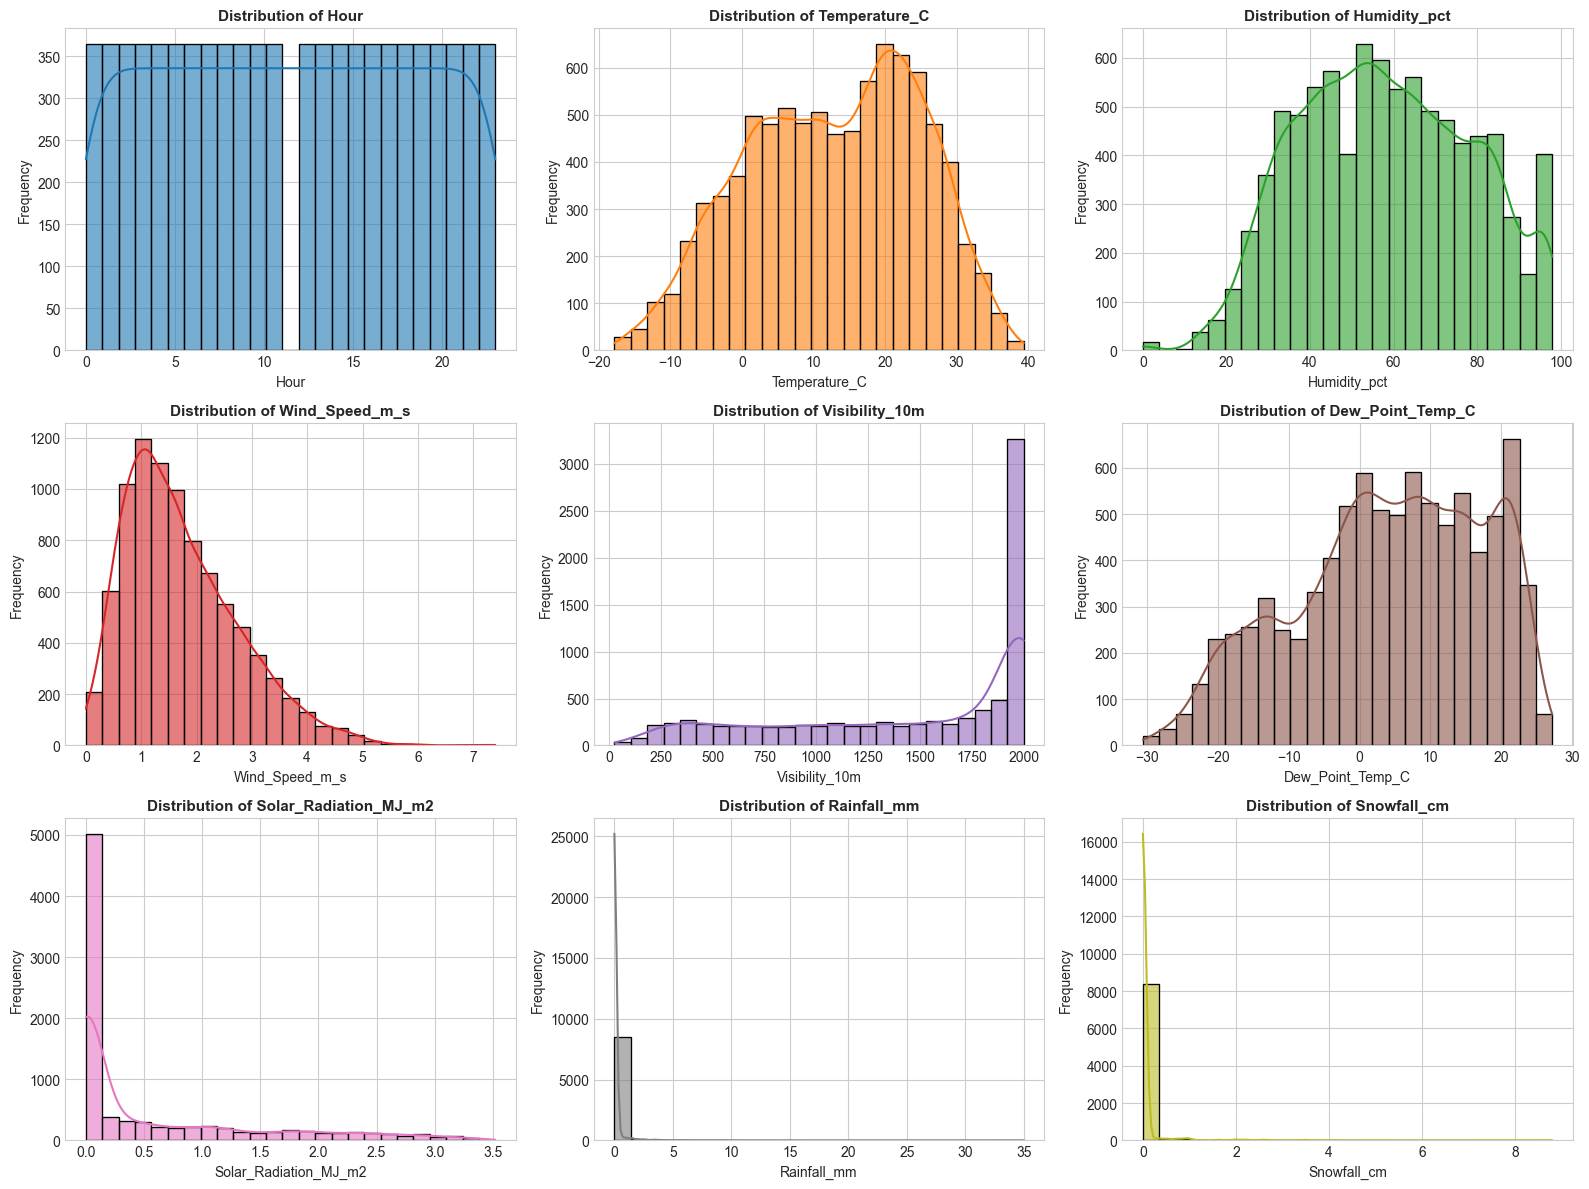

In [6]:
numerical_cols = [
    'Hour', 'Temperature_C', 'Humidity_pct', 'Wind_Speed_m_s', 
    'Visibility_10m', 'Dew_Point_Temp_C', 'Solar_Radiation_MJ_m2', 
    'Rainfall_mm', 'Snowfall_cm'
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    ax = axes[idx]
    sns.histplot(df[col], kde=True, ax=ax, color=palette[idx % len(palette)], bins=25, alpha=0.6)
    ax.set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)

plt.tight_layout()
plt.show()

**Observation**:
1. `Hour` displays a completely uniform distribution ranging from 0 to 23 (exactly 365 observations per hour), representing regular hourly data capture.
2. `Temperature_C` and `Dew_Point_Temp_C` exhibit approximately symmetric, bell-shaped distributions spanning from -17.8°C to 39.4°C and -30.5°C to 27.2°C, respectively.
3. `Humidity_pct` ranges from 0% to 98% with an approximately normal spread centered near 58%.
4. `Wind_Speed_m_s` and `Visibility_10m` show moderate right and left skewness, respectively, with visibility capping at the sensor ceiling of 2,000 (10m units = 20 km).
5. `Solar_Radiation_MJ_m2`, `Rainfall_mm`, and `Snowfall_cm` exhibit heavy zero concentration, as night hours have zero solar radiation, and precipitation occurs in a minority of recorded hours.

**ML Implication**:
- Features operate on substantially different numerical scales (e.g., Visibility up to 2000 vs. Rainfall up to 35 mm). Feature standardization is essential for distance-based and margin-based algorithms (KNN, SVR) and regularized linear models (Ridge, Lasso, ElasticNet).
- The extreme zero concentration in precipitation features means tree-based splits can readily isolate wet vs. dry conditions, whereas linear models will treat them as continuous slopes.

#### 5.2 Categorical Predictor Feature Distributions
We examine the distribution of the three categorical features: `Seasons`, `Holiday`, and `Functioning_Day`.

C:\Users\naren\AppData\Local\Temp\ipykernel_22504\3752125448.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
C:\Users\naren\AppData\Local\Temp\ipykernel_22504\3752125448.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
C:\Users\naren\AppData\Local\Temp\ipykernel_22504\3752125448.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')


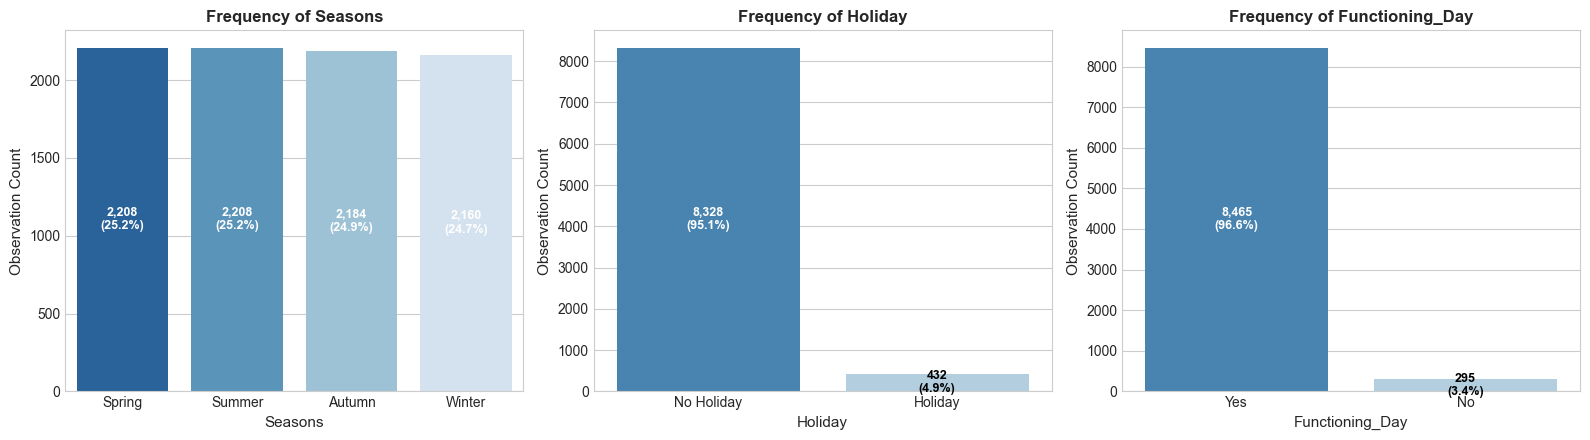

In [7]:
categorical_cols = ['Seasons', 'Holiday', 'Functioning_Day']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, col in enumerate(categorical_cols):
    ax = axes[idx]
    counts = df[col].value_counts()
    percentages = (counts / len(df)) * 100
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette='Blues_r')
    ax.set_title(f'Frequency of {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=11)
    ax.set_ylabel('Observation Count', fontsize=11)
    
    # Annotate bar counts and percentages
    for p_idx, p in enumerate(ax.patches):
        height = p.get_height()
        pct = percentages.iloc[p_idx]
        ax.annotate(f'{int(height):,}\n({pct:.1f}%)',
                    (p.get_x() + p.get_width() / 2., height / 2.),
                    ha='center', va='center', fontsize=9, color='white' if pct > 20 else 'black',
                    fontweight='bold')

plt.tight_layout()
plt.show()

**Observation**:
1. `Seasons` is balanced almost equally across the four seasons: Spring (25.2%), Summer (25.2%), Autumn (24.9%), and Winter (24.7%).
2. `Holiday` is heavily skewed toward non-holidays: `No Holiday` accounts for 8,328 records (95.1%), while `Holiday` accounts for 432 records (4.9%).
3. `Functioning_Day` indicates that the rental service was operational for 8,465 hours (96.6%) and non-operational (`No`) for 295 hours (3.4%). Notably, when `Functioning_Day == 'No'`, the rented bike count is strictly 0 in every single record.

**ML Implication**:
- `Seasons` will be one-hot encoded to allow algorithms to learn distinct seasonal coefficients or partition points.
- `Functioning_Day` is a dominant deterministic gating variable. Retaining and one-hot encoding this variable allows linear and tree models to predict 0 or near-0 demand when the system is inactive.
- The low frequency of `Holiday` suggests it may have subtle, localized interaction effects that ensemble models can capture.

#### 5.3 Temporal Coverage and Timeline Sampling
We inspect the time dimension across the dataset to confirm whether records span an unbroken chronological sequence.

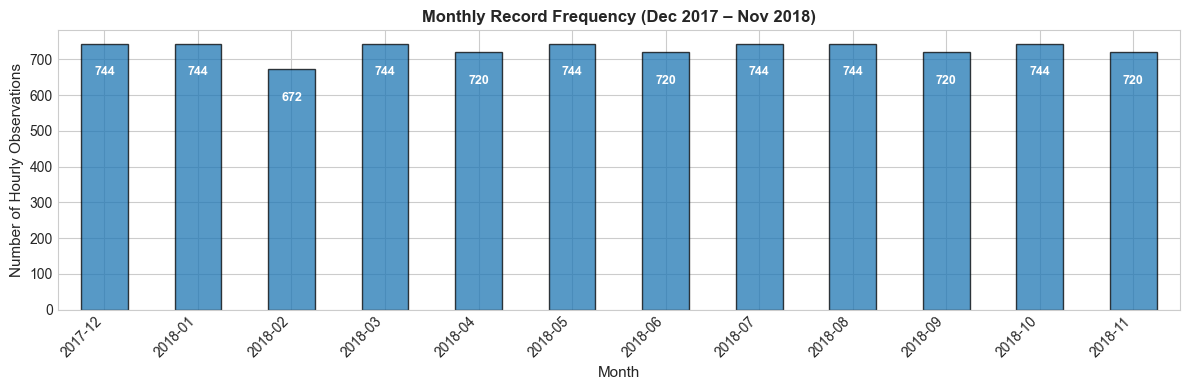

In [8]:
# Inspect date continuity
df['Date_dt'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
daily_counts = df.groupby(df['Date_dt'].dt.to_period('M')).size()

fig, ax = plt.subplots(figsize=(12, 4))
daily_counts.plot(kind='bar', ax=ax, color='#1f77b4', edgecolor='black', alpha=0.75)
ax.set_title('Monthly Record Frequency (Dec 2017 – Nov 2018)', fontsize=12, fontweight='bold')
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Number of Hourly Observations', fontsize=11)
ax.set_xticklabels([str(p) for p in daily_counts.index], rotation=45, ha='right')

for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2., p.get_height() - 80),
                ha='center', va='center', fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Observation**:
The dataset encompasses exactly 12 full months from December 2017 through November 2018. Each month contains between 672 and 744 observations, corresponding precisely to 24 hours $\times$ the exact number of days in each month (e.g., 28 days $\times$ 24 = 672 in February 2018; 31 days $\times$ 24 = 744 in January 2018).

**ML Implication**:
The dataset contains zero missing days or gaps in temporal logging. However, because standard random splitting could theoretically cause temporal autocorrelation leakage if dates are reused without care, we will engineer standalone calendar features (Month, Day of Week, Is Weekend, Rush Hour) so models learn structural temporal patterns rather than rote chronological memorization.

#### 5.4 Target Variable Distribution (`Rented_Bike_Count`)
We plot the distribution of the target variable to evaluate its central tendency, spread, and modal peaks.

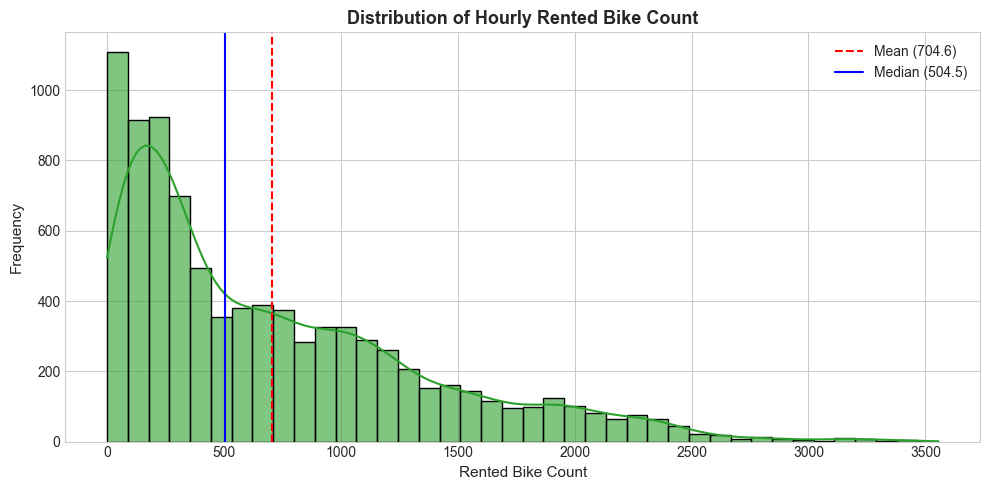

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df['Rented_Bike_Count'], kde=True, ax=ax, color='#2ca02c', bins=40, alpha=0.6)
ax.axvline(df['Rented_Bike_Count'].mean(), color='red', linestyle='--', linewidth=1.5, label=f"Mean ({df['Rented_Bike_Count'].mean():.1f})")
ax.axvline(df['Rented_Bike_Count'].median(), color='blue', linestyle='-', linewidth=1.5, label=f"Median ({df['Rented_Bike_Count'].median():.1f})")
ax.set_title('Distribution of Hourly Rented Bike Count', fontsize=13, fontweight='bold')
ax.set_xlabel('Rented Bike Count', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

**Observation**:
The target variable exhibits a pronounced positive skewness (skewness = +1.15). The mode occurs in the lowest rental bracket (including zero rentals on non-functioning days and deep nighttime hours), followed by an extended right tail reaching up to 3,556 rentals during peak commuting conditions. The mean (704.6) is pulled substantially above the median (504.5).

**ML Implication**:
The substantial skewness indicates that standard uniform random train/test splitting carries a risk of generating unbalanced test sets with under-represented extreme peak observations. Stratified sampling using target quantile bins is therefore methodologically justified to guarantee consistent demand distributions across both train and test splits.

#### 5.5 Correlation Heatmap and Multicollinearity Analysis
We compute the pairwise Pearson correlation coefficients across all numerical features and the target.

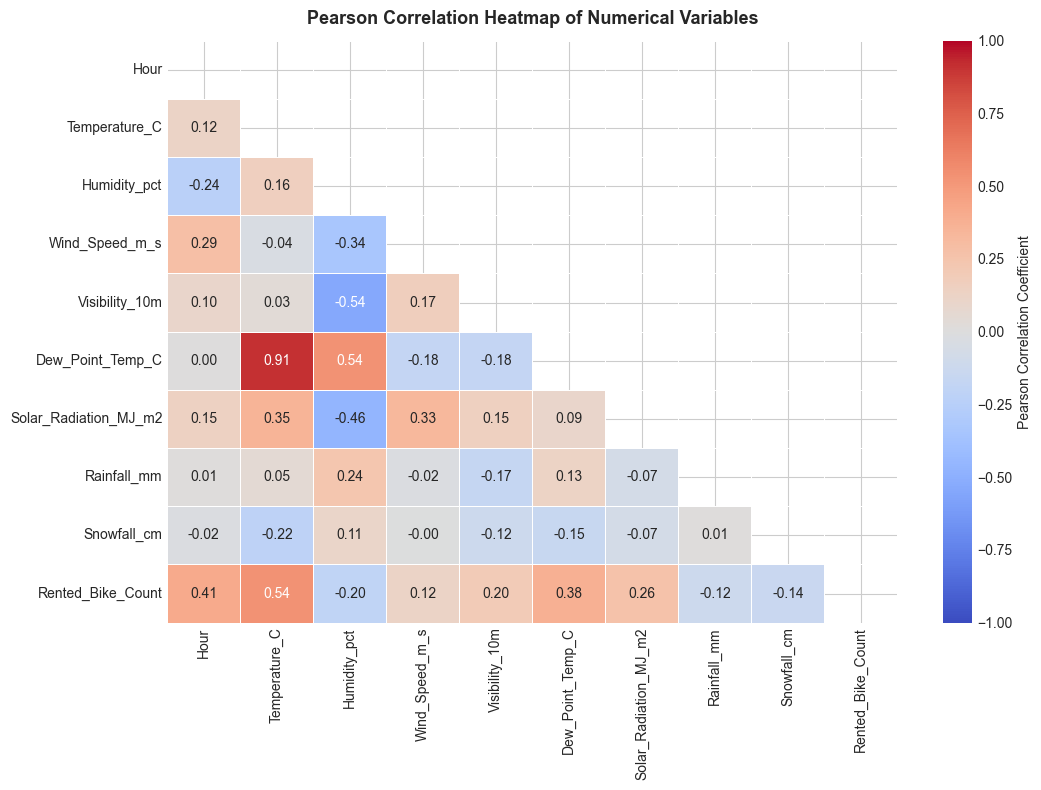

In [10]:
plt.figure(figsize=(11, 8))
corr_matrix = df[numerical_cols + ['Rented_Bike_Count']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, 
    mask=mask, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Pearson Correlation Heatmap of Numerical Variables', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

**Observation**:
1. `Temperature_C` exhibits the strongest linear correlation with `Rented_Bike_Count` ($r = +0.54$), followed by `Hour` ($r = +0.41$) and `Solar_Radiation_MJ_m2` ($r = +0.26$).
2. `Humidity_pct` has a moderate negative correlation with bike rentals ($r = -0.38$), while `Rainfall_mm` and `Snowfall_cm` also display negative associations ($r = -0.12$ and $r = -0.14$).
3. **Severe Collinearity**: `Temperature_C` and `Dew_Point_Temp_C` share an extremely high collinearity ($r = +0.91$).

**ML Implication**:
- The high collinearity ($r = 0.91$) between temperature and dew point temperature introduces multicollinearity for unregularized linear models, potentially inflating coefficient variances.
- Regularized linear models (Ridge with L2, Lasso with L1, ElasticNet) and tree ensembles are expected to handle this redundancy effectively.

#### 5.6 Continuous Numerical Feature-vs-Target Scatter Plots
The capstone guidelines require at least two genuine continuous numerical feature-vs-target scatter plots. We examine three primary drivers: Temperature, Solar Radiation, and Humidity.

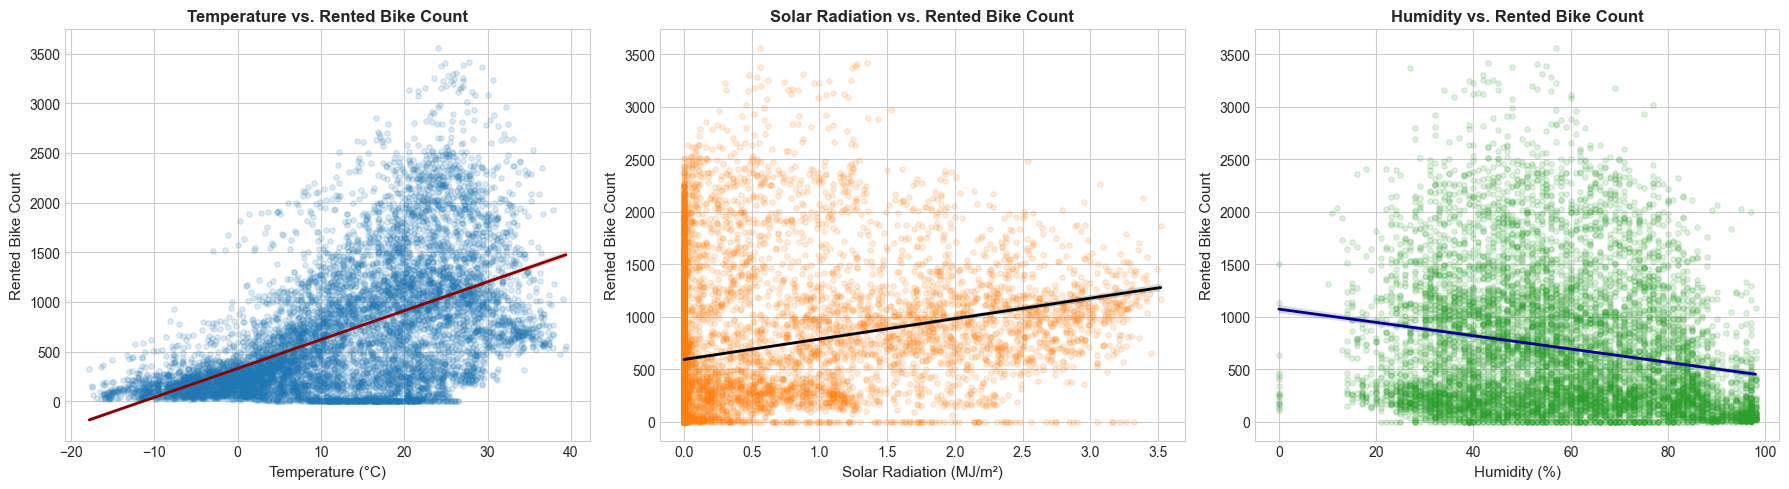

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Temperature vs Rented Bike Count
sns.regplot(
    data=df, x='Temperature_C', y='Rented_Bike_Count', ax=axes[0],
    scatter_kws={'alpha': 0.15, 'color': '#1f77b4', 's': 15},
    line_kws={'color': 'darkred', 'linewidth': 2}
)
axes[0].set_title('Temperature vs. Rented Bike Count', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Temperature (°C)', fontsize=11)
axes[0].set_ylabel('Rented Bike Count', fontsize=11)

# Plot 2: Solar Radiation vs Rented Bike Count
sns.regplot(
    data=df, x='Solar_Radiation_MJ_m2', y='Rented_Bike_Count', ax=axes[1],
    scatter_kws={'alpha': 0.15, 'color': '#ff7f0e', 's': 15},
    line_kws={'color': 'black', 'linewidth': 2}
)
axes[1].set_title('Solar Radiation vs. Rented Bike Count', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Solar Radiation (MJ/m²)', fontsize=11)
axes[1].set_ylabel('Rented Bike Count', fontsize=11)

# Plot 3: Humidity vs Rented Bike Count
sns.regplot(
    data=df, x='Humidity_pct', y='Rented_Bike_Count', ax=axes[2],
    scatter_kws={'alpha': 0.15, 'color': '#2ca02c', 's': 15},
    line_kws={'color': 'darkblue', 'linewidth': 2}
)
axes[2].set_title('Humidity vs. Rented Bike Count', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Humidity (%)', fontsize=11)
axes[2].set_ylabel('Rented Bike Count', fontsize=11)

plt.tight_layout()
plt.show()

**Observation**:
1. **Temperature vs. Rentals**: Rental demand increases steadily as temperature rises from -15°C up to approximately 25°C. Beyond 28°C–30°C, demand flattens and slightly disperses, revealing a mild non-linear plateau during hot summer peaks.
2. **Solar Radiation vs. Rentals**: Zero solar radiation spans all nighttime hours where demand is variable but generally depressed. As solar radiation increases from 0.5 to 3.5 MJ/m², peak rental counts increase notably.
3. **Humidity vs. Rentals**: A clear downward trend appears as humidity exceeds 70%–80%. Extremely humid air often coincides with precipitation or uncomfortable muggy conditions, suppressing cycling activity.

**ML Implication**:
The relationship between weather variables and rental demand is largely monotonic but exhibits subtle non-linear boundaries (e.g., extreme heat dampening demand; threshold effect of high humidity). This suggests non-linear architectures (Polynomial Regression, Decision Trees, Random Forests, Gradient Boosting) will likely outperform simple linear fits.

### 6. Data Cleaning
We formalize the data cleaning findings and evaluate outliers across numerical predictors and the target variable.

In [12]:
# Explicitly verify missing values and duplicate rows
missing_counts = df.isnull().sum()
duplicate_rows = df.duplicated().sum()

print("--- DATA INTEGRITY VERIFICATION ---")
print(f"Total missing values across all columns: {missing_counts.sum()}")
print(f"Total duplicate rows in dataset: {duplicate_rows}")

# Outlier analysis using the Interquartile Range (IQR) method
iqr_records = []
for col in numerical_cols + ['Rented_Bike_Count']:
    q25 = df[col].quantile(0.25)
    q75 = df[col].quantile(0.75)
    iqr = q75 - q25
    lower_bound = q25 - 1.5 * iqr
    upper_bound = q75 + 1.5 * iqr
    outlier_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    pct_outliers = (outlier_count / len(df)) * 100
    iqr_records.append({
        'Feature': col,
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': outlier_count,
        'Outlier %': round(pct_outliers, 2)
    })

outlier_df = pd.DataFrame(iqr_records)
display(outlier_df)

--- DATA INTEGRITY VERIFICATION ---
Total missing values across all columns: 0
Total duplicate rows in dataset: 0


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Hour,-11.50,34.50,0,0.00
1,Temperature_C,-25.00,51.00,0,0.00
2,Humidity_pct,-6.00,122.00,0,0.00
3,Wind_Speed_m_s,-1.20,4.40,161,1.84
4,Visibility_10m,-650.00,3590.00,0,0.00
5,Dew_Point_Temp_C,-33.95,44.05,0,0.00
6,Solar_Radiation_MJ_m2,-1.40,2.33,641,7.32
7,Rainfall_mm,0.00,0.00,528,6.03
8,Snowfall_cm,0.00,0.00,443,5.06
9,Rented_Bike_Count,-1120.38,2376.62,158,1.80


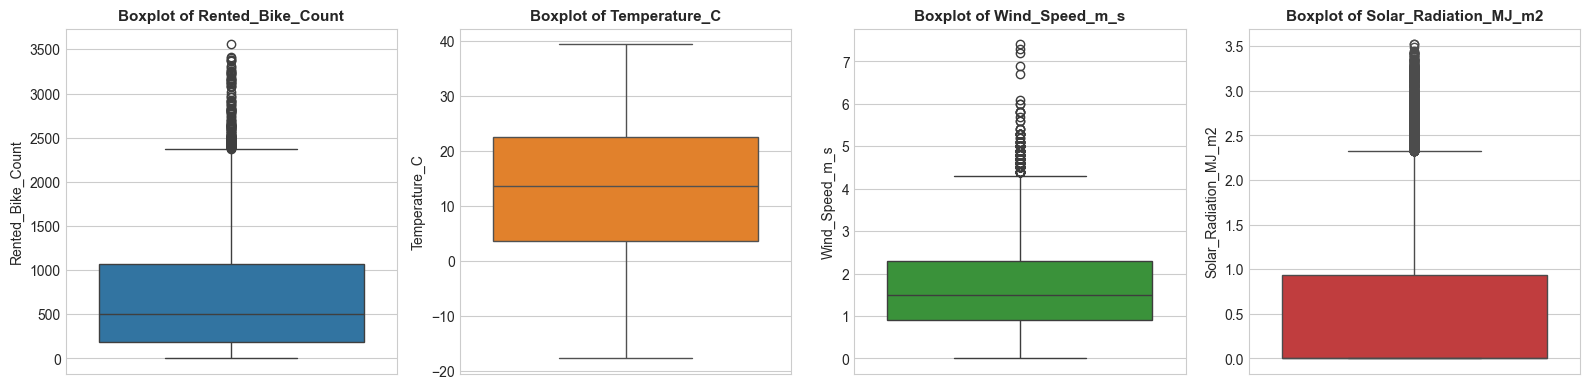

In [13]:
# Boxplot visualization of key variables to inspect distribution tails
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
box_cols = ['Rented_Bike_Count', 'Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_MJ_m2']

for idx, col in enumerate(box_cols):
    sns.boxplot(y=df[col], ax=axes[idx], color=palette[idx])
    axes[idx].set_title(f'Boxplot of {col}', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel(col, fontsize=10)

plt.tight_layout()
plt.show()

**Observation & Outlier Treatment Decision**:
The IQR audit identifies 158 observations (1.80%) in `Rented_Bike_Count` exceeding the statistical threshold of 2,423 rentals, 161 observations (1.84%) in `Wind_Speed_m_s`, and 641 observations (7.32%) in `Solar_Radiation_MJ_m2`.

**Critical Justification**:
These values represent **legitimate real-world demand surges and natural meteorological variations**, not measurement or transcription errors. Extreme bike rentals occur predictably during warm summer evening rush hours when weather is ideal. Truncating or deleting these points would remove genuine peak-demand scenarios that municipal bike planners must prepare for. Therefore, all legitimate data points are retained.

### 7. Train/Test Split (with Quantile Stratification)
To evaluate models without data leakage, we split the dataset into an **80% training set (7,008 samples)** and a **held-out 20% test set (1,752 samples)**.

**Quantile Stratification Methodology**:
Because `Rented_Bike_Count` is a continuous, right-skewed variable, standard random splitting risks uneven distribution of rare peak-demand observations between sets. We partition the continuous target into 10 quantile bins solely to stratify the split via `train_test_split(..., stratify=y_bins, random_state=42)`.

> [!IMPORTANT]
> The quantile bin column is discarded immediately after partitioning. It is never supplied to any model or preprocessing transformer, preventing any data leakage.

In [14]:
from sklearn.model_selection import train_test_split

# Separate raw features and target variable
target_col = 'Rented_Bike_Count'
y = df[target_col].copy()
X_raw = df.drop(columns=[target_col]).copy()

# Generate temporary quantile bins for stratified splitting
y_strat_bins = pd.qcut(y, q=10, duplicates='drop')

# Execute stratified 80:20 split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y_strat_bins
)

print(f"Training feature set shape: {X_train_raw.shape} | Training labels: {y_train.shape}")
print(f"Test feature set shape:     {X_test_raw.shape} | Test labels:     {y_test.shape}")

# Verify distributional similarity across train and test sets
split_check = pd.DataFrame({
    'Metric': ['Mean', 'Std Dev', 'Median', 'Min', 'Max'],
    'Full Dataset': [y.mean(), y.std(), y.median(), y.min(), y.max()],
    'Train Set': [y_train.mean(), y_train.std(), y_train.median(), y_train.min(), y_train.max()],
    'Test Set': [y_test.mean(), y_test.std(), y_test.median(), y_test.min(), y_test.max()]
}).round(2)
display(split_check)

Training feature set shape: (7008, 14) | Training labels: (7008,)
Test feature set shape:     (1752, 14) | Test labels:     (1752,)


,Metric,Full Dataset,Train Set,Test Set
0,Mean,704.6,704.81,703.79
1,Std Dev,645.0,645.14,644.60
2,Median,504.5,504.50,504.00
3,Min,0.0,0.00,0.00
4,Max,3556.0,3556.00,3380.00


### 8. Feature Engineering
We engineer domain-informed temporal features from `Date` and `Hour`:
1. **Calendar Date Components**:
   - `Month` (1–12): Captures macro-seasonal transitions beyond the 4 discrete seasons.
   - `Day` (1–31): Captures intra-month dynamics.
   - `DayOfWeek` (0–6): Represents day-to-day commute patterns.
   - `Is_Weekend` (0 or 1): Binary indicator (Saturday=5, Sunday=6) reflecting leisure vs. commuter profiles.
2. **Commuter Rush Hour Indicator (`Rush_Hour`)**:
   - Commuter bike traffic peaks during morning (08:00–09:59) and evening (18:00–20:59) on working weekdays.
3. **Cyclical Hour Representations (`Hour_sin`, `Hour_cos`)**:
   - Hour is inherently cyclical (hour 23 is immediately adjacent to hour 0). Linear models treat 23 and 0 as maximally distant. Applying sine and cosine harmonic transformations preserves this continuous circular topology:
     $$\text{Hour}_{\sin} = \sin\left(\frac{2\pi \times \text{Hour}}{24}\right), \quad \text{Hour}_{\cos} = \cos\left(\frac{2\pi \times \text{Hour}}{24}\right)$$

**Leakage Prevention**:
All transformations rely purely on the timestamp of the observation itself; no aggregations across the dataset or target values are computed.

In [15]:
def engineer_features(data):
    df_out = data.copy()
    
    # Parse date if not already datetime
    if not pd.api.types.is_datetime64_any_dtype(df_out['Date']):
        dt_series = pd.to_datetime(df_out['Date'], format='%d/%m/%Y')
    else:
        dt_series = df_out['Date']
        
    df_out['Month'] = dt_series.dt.month
    df_out['Day'] = dt_series.dt.day
    df_out['DayOfWeek'] = dt_series.dt.dayofweek
    df_out['Is_Weekend'] = (df_out['DayOfWeek'] >= 5).astype(int)
    
    # Cyclical hour encoding
    df_out['Hour_sin'] = np.sin(2 * np.pi * df_out['Hour'] / 24.0)
    df_out['Hour_cos'] = np.cos(2 * np.pi * df_out['Hour'] / 24.0)
    
    # Commuter Rush Hour indicator (Weekdays: 8-9 AM, 6-8 PM)
    df_out['Rush_Hour'] = (
        ((df_out['Hour'].isin([8, 9])) | (df_out['Hour'].isin([18, 19, 20]))) & 
        (df_out['Is_Weekend'] == 0)
    ).astype(int)
    
    # Drop raw date column and temporary datetime column
    cols_to_drop = [c for c in ['Date', 'Date_dt'] if c in df_out.columns]
    df_out = df_out.drop(columns=cols_to_drop)
    
    return df_out

# Apply feature engineering to train and test sets independently
X_train_fe = engineer_features(X_train_raw)
X_test_fe = engineer_features(X_test_raw)

print(f"Feature engineering complete. Columns: {X_train_fe.columns.tolist()}")
print(f"Engineered training shape: {X_train_fe.shape} | Test shape: {X_test_fe.shape}")
X_train_fe.head(3)

Feature engineering complete. Columns: ['Hour', 'Temperature_C', 'Humidity_pct', 'Wind_Speed_m_s', 'Visibility_10m', 'Dew_Point_Temp_C', 'Solar_Radiation_MJ_m2', 'Rainfall_mm', 'Snowfall_cm', 'Seasons', 'Holiday', 'Functioning_Day', 'Month', 'Day', 'DayOfWeek', 'Is_Weekend', 'Hour_sin', 'Hour_cos', 'Rush_Hour']
Engineered training shape: (7008, 19) | Test shape: (1752, 19)


,Hour,Temperature_C,Humidity_pct,Wind_Speed_m_s,Visibility_10m,Dew_Point_Temp_C,Solar_Radiation_MJ_m2,Rainfall_mm,Snowfall_cm,Seasons,Holiday,Functioning_Day,Month,Day,DayOfWeek,Is_Weekend,Hour_sin,Hour_cos,Rush_Hour
6473,17,24.9,82,0.9,2000,21.6,0.67,0.0,0.0,Summer,No Holiday,Yes,8,27,0,0,-0.965926,-0.258819,0
6283,19,29.7,55,2.5,2000,19.6,0.23,0.0,0.0,Summer,No Holiday,Yes,8,19,6,1,-0.965926,0.258819,0
8404,4,7.1,64,0.6,663,0.7,0.00,0.0,0.0,Autumn,No Holiday,Yes,11,16,4,0,0.866025,0.500000,0


### 9. Encoding and Preprocessing Pipeline
We build a robust scikit-learn `ColumnTransformer`:
- **Categorical Columns** (`Seasons`, `Holiday`, `Functioning_Day`): Processed via `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)` to prevent collinear dummy traps.
- **Numerical Columns**: Standardized to zero mean and unit variance using `StandardScaler()`.

> [!CAUTION]
> **Strict Leakage Prevention**:
> `preprocessor.fit()` is invoked **strictly on `X_train_fe`**. The fitted transformer is then used to `transform()` both `X_train_fe` and `X_test_fe`.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_features = ['Seasons', 'Holiday', 'Functioning_Day']
numerical_features = [c for c in X_train_fe.columns if c not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# Fit strictly on training data
X_train_prep = preprocessor.fit_transform(X_train_fe)
X_test_prep = preprocessor.transform(X_test_fe)

# Retrieve transformed column names
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(categorical_features).tolist()
all_feature_names = numerical_features + cat_feature_names

print(f"Preprocessed feature count: {X_train_prep.shape[1]}")
print("Feature names after preprocessing:", all_feature_names)

Preprocessed feature count: 21
Feature names after preprocessing: ['Hour', 'Temperature_C', 'Humidity_pct', 'Wind_Speed_m_s', 'Visibility_10m', 'Dew_Point_Temp_C', 'Solar_Radiation_MJ_m2', 'Rainfall_mm', 'Snowfall_cm', 'Month', 'Day', 'DayOfWeek', 'Is_Weekend', 'Hour_sin', 'Hour_cos', 'Rush_Hour', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Holiday_No Holiday', 'Functioning_Day_Yes']
